# Energy Demand Forecasting

Forecasting 60 months of monthly **gas, electricity and water** consumption with `statsmodels`: a Simple Exponential Smoothing baseline, then Holt-Winters tuned on a validation set and checked on 60 held-out months.

**Data:** `data/energy_consumption.csv`, 397 monthly readings from January 1990 to January 2023.

| Target | Unit |
|---|---|
| Gas consumption | tons |
| Electricity consumption | MWh |
| Water consumption | tons |

**Workflow**
1. Load the data and parse the dates correctly
2. Explore trend and seasonality
3. Decompose each series into trend, seasonal and residual parts
4. Test for stationarity (ADF test)
5. Split chronologically into train, validation and a 60-month test set
6. Baseline: Simple Exponential Smoothing, plus a seasonal naive benchmark
7. Improve: Holt-Winters, tuned on the validation set
8. Refit on train + validation and forecast the 60 test months
9. Check the residuals

---
## 1. Load and prepare the data

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import shapiro
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)
plt.style.use('seaborn-v0_8')
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('data/energy_consumption.csv')
print(f"Shape: {df.shape}")
df.head()

Shape: (397, 4)


,DATE,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
0,1/1/1990,18.0,725.1,548.8
1,1/2/1990,15.8,706.7,640.7
2,1/3/1990,17.3,624.5,511.1
3,1/4/1990,18.9,574.7,515.3
4,1/5/1990,22.0,553.2,488.4


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   DATE                           397 non-null    object 
 1   Gas Consumption (tons)         397 non-null    float64
 2   Electricity Consumption (MWh)  397 non-null    float64
 3   Water Consumption (tons)       397 non-null    float64
dtypes: float64(3), object(1)
memory usage: 12.5+ KB


**Observations**

- 397 rows and no missing values. The three consumption columns are numeric.
- `DATE` is a string in **day/month/year** format: `1/2/1990` is 1 February 1990, not 2 January. It has to be parsed with `dayfirst=True`.
- The check at the end of the next cell matters. With the wrong date format, setting a monthly frequency leaves 363 of 397 months empty, and filling them by interpolation hides the problem completely. That was a bug in my first version (see the README).

In [4]:
# Dates are day/month/year: '1/2/1990' is 1 February 1990.
# Without dayfirst=True, pandas reads it as 2 January 1990, and setting a monthly
# frequency then keeps only the 34 January rows (see the README).
df['DATE'] = pd.to_datetime(df['DATE'], dayfirst=True)
df = df.sort_values('DATE').set_index('DATE')

# One row per month start
df = df.asfreq('MS')

print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")
print(f"Months: {len(df)}")
print("\nMissing values after setting a monthly frequency:")
print(df.isna().sum())

# Guard against the date bug: every month must hold a real reading, not a gap to fill
assert df.notna().all().all(), "Some months are missing. Check the date format."

Date range: 1990-01-01 to 2023-01-01
Months: 397

Missing values after setting a monthly frequency:
Gas Consumption (tons)           0
Electricity Consumption (MWh)    0
Water Consumption (tons)         0
dtype: int64


---
## 2. Exploratory data analysis

Looking for trend (long-term direction), seasonality (a pattern that repeats every year), volatility and outliers.

In [5]:
df.describe().round(1)

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
count,397.0,397.0,397.0
mean,23.8,888.5,485.0
std,4.9,153.9,133.9
min,11.6,553.2,44.4
25%,20.2,771.1,384.4
50%,23.5,897.8,487.4
75%,27.9,1005.2,580.2
max,46.0,1294.0,811.0


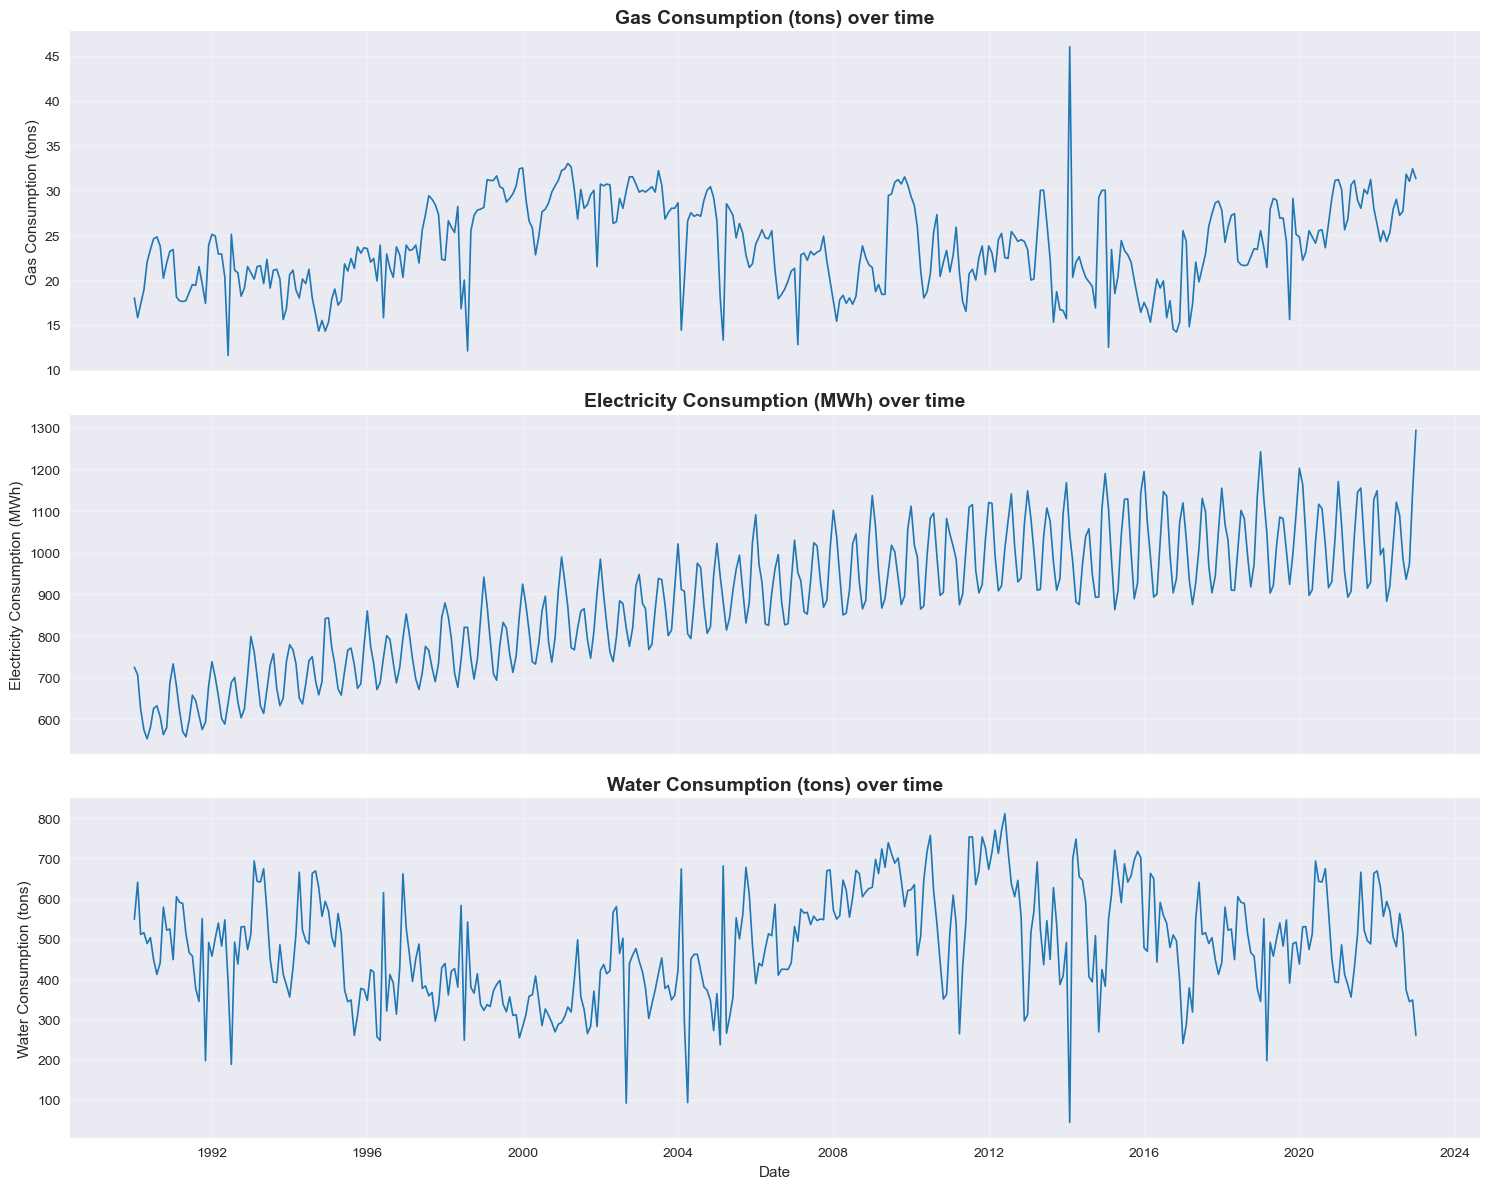

In [6]:
targets = ['Gas Consumption (tons)', 'Electricity Consumption (MWh)', 'Water Consumption (tons)']

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
for idx, target in enumerate(targets):
    axes[idx].plot(df.index, df[target], color='tab:blue', linewidth=1.2)
    axes[idx].set_title(f'{target} over time', fontsize=14, fontweight='bold')
    axes[idx].set_ylabel(target)
    axes[idx].grid(True, alpha=0.3)
plt.xlabel('Date')
plt.tight_layout()
plt.show()

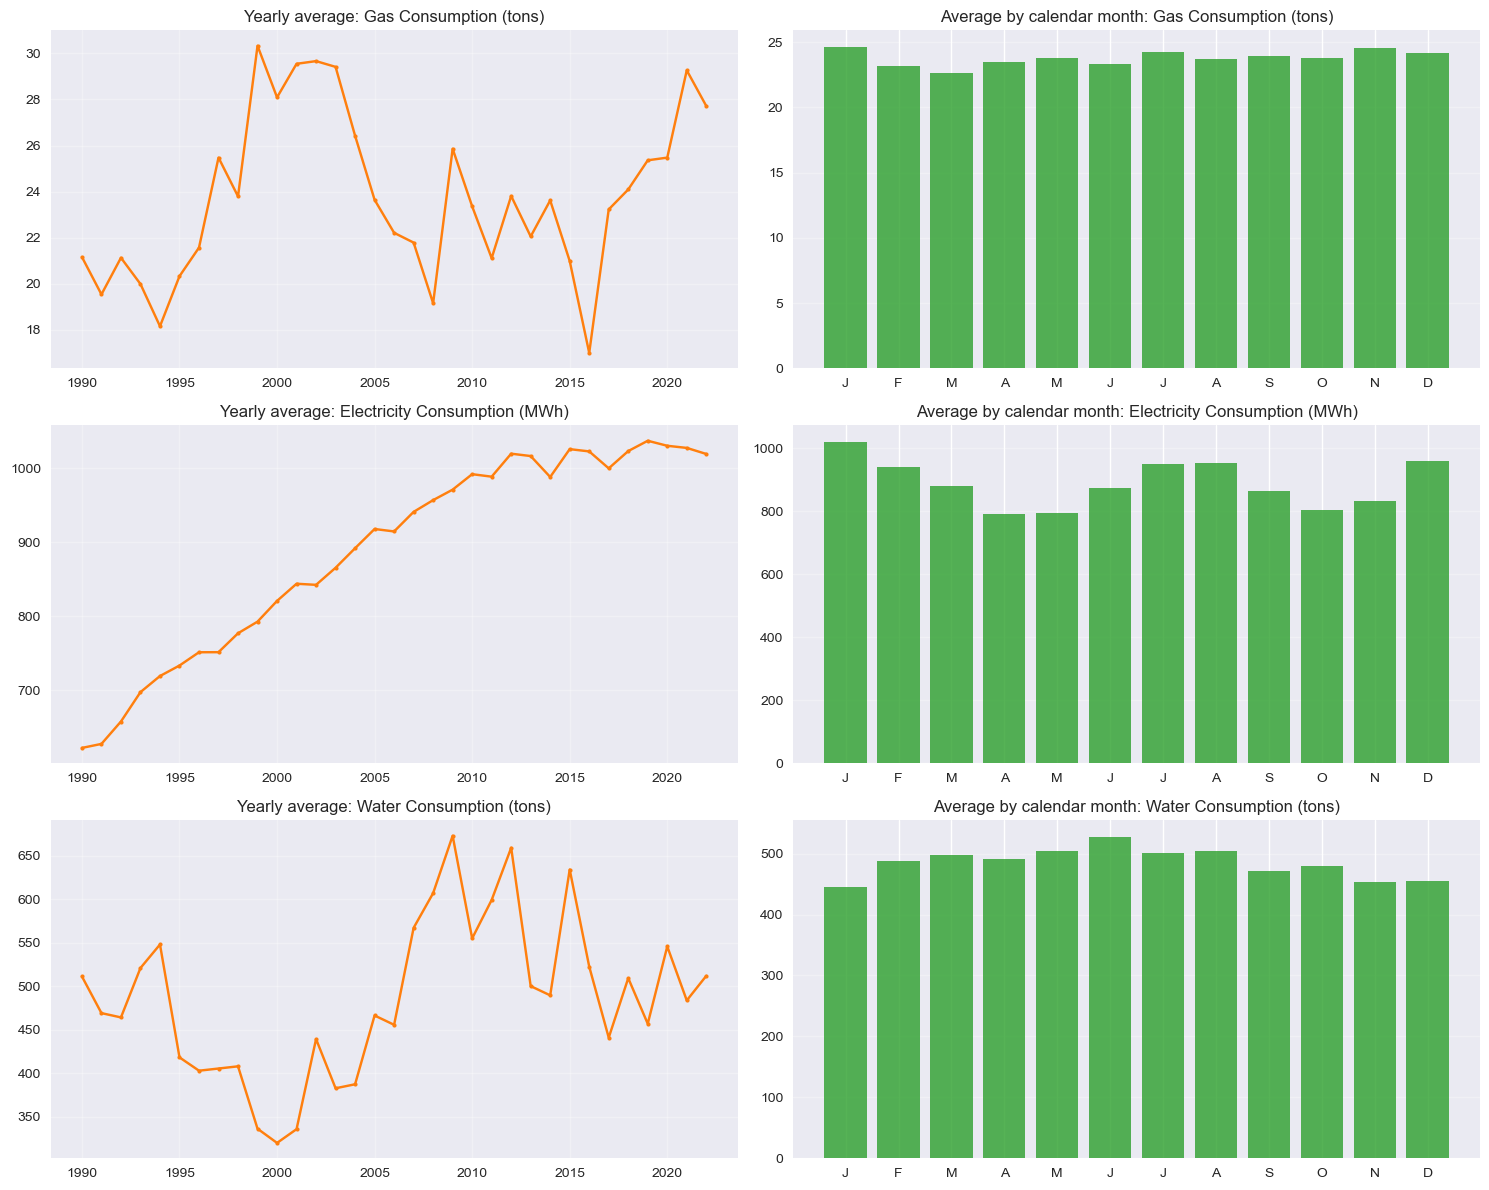

In [7]:
# Yearly averages show the long-term trend (2023 is left out because it only has January)
df_yearly = df.loc[:'2022'].resample('YE').mean()

# Average for each calendar month shows the seasonal pattern
df_monthly_profile = df.groupby(df.index.month).mean()

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for idx, target in enumerate(targets):
    axes[idx, 0].plot(df_yearly.index.year, df_yearly[target], color='tab:orange', marker='o', markersize=3)
    axes[idx, 0].set_title(f'Yearly average: {target}', fontsize=12)
    axes[idx, 0].grid(True, alpha=0.3)

    axes[idx, 1].bar(df_monthly_profile.index, df_monthly_profile[target], color='tab:green', alpha=0.8)
    axes[idx, 1].set_title(f'Average by calendar month: {target}', fontsize=12)
    axes[idx, 1].set_xticks(range(1, 13))
    axes[idx, 1].set_xticklabels(['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    axes[idx, 1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Observations**

**Electricity**
- **Trend:** a strong rise from about 620 MWh a month (1990 average) to about 1,020 MWh by 2012, then roughly flat.
- **Seasonality:** very clear, with **two peaks a year**: January (and December) and July–August, with dips in April–May and October. That fits heating demand in winter and cooling demand in summer.
- **Volatility:** the seasonal swings grow slightly as the level rises.

**Gas**
- **Trend:** no steady direction. It moves in multi-year waves: around 18–21 tons in the early 1990s, about 28–30 from 1999 to 2003, down to about 17 in 2016, then rising again.
- **Seasonality:** almost none. Every calendar month averages between 22.6 and 24.7 tons.
- **Outliers:** sharp one-month drops, and a one-month spike to 46 tons in February 2014.

**Water**
- **Trend:** also multi-year swings: about 320 tons around 2000, peaking near 670 in 2009, then back around 500.
- **Seasonality:** weak, with slightly higher months around May–August.
- **Outliers:** a few very low months, including 44.4 tons in February 2014 against a typical 400–600.

---
## 3. Time series decomposition

Splitting each series into a **trend**, a repeating **seasonal** pattern and a **residual** (what's left over). This shows which components a model needs to capture.

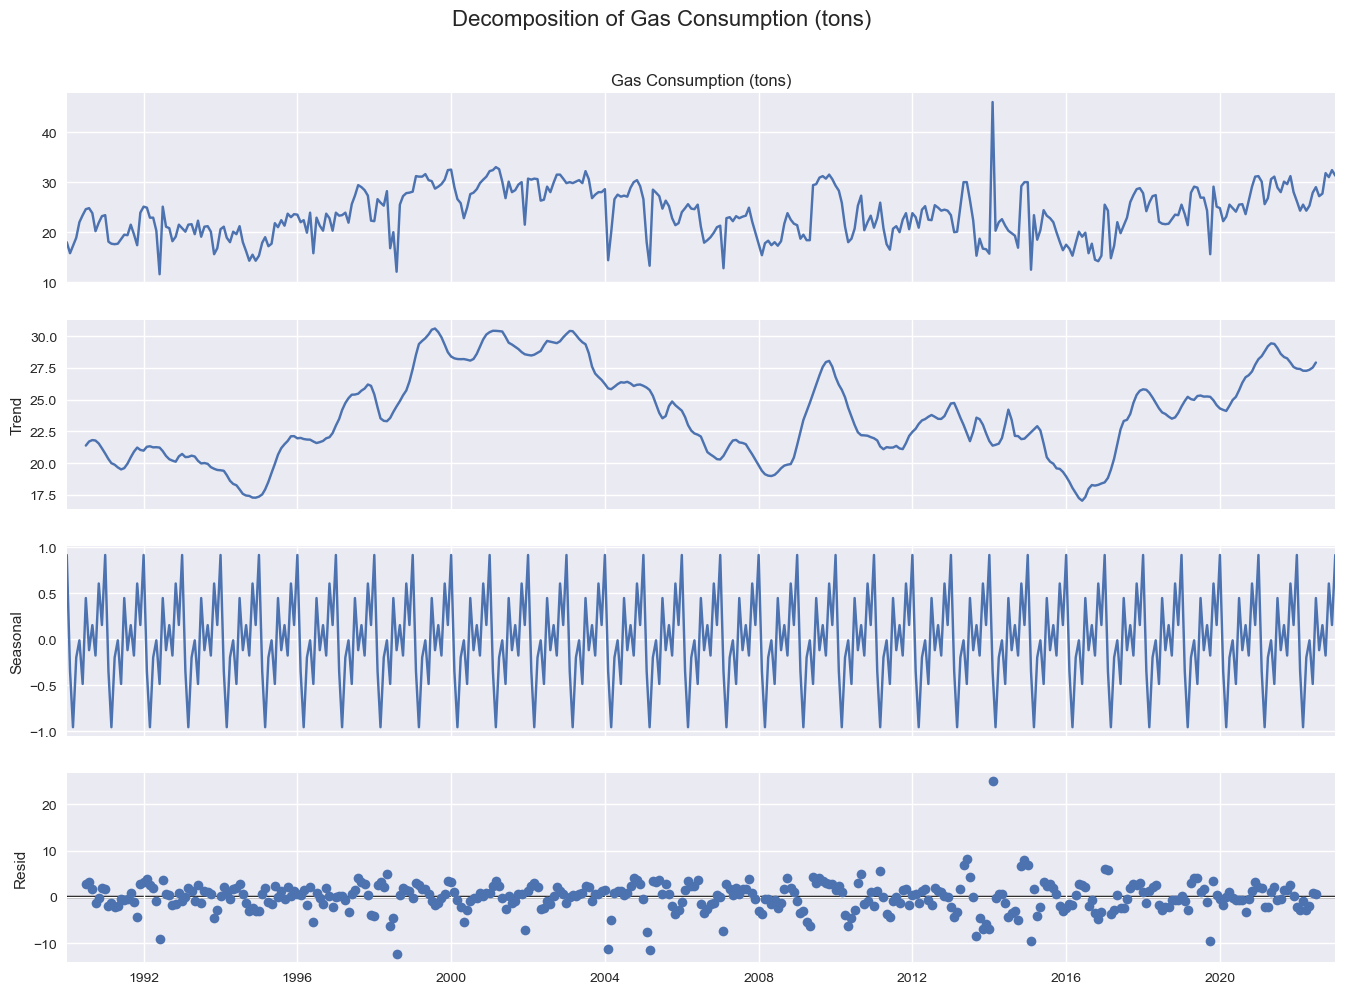

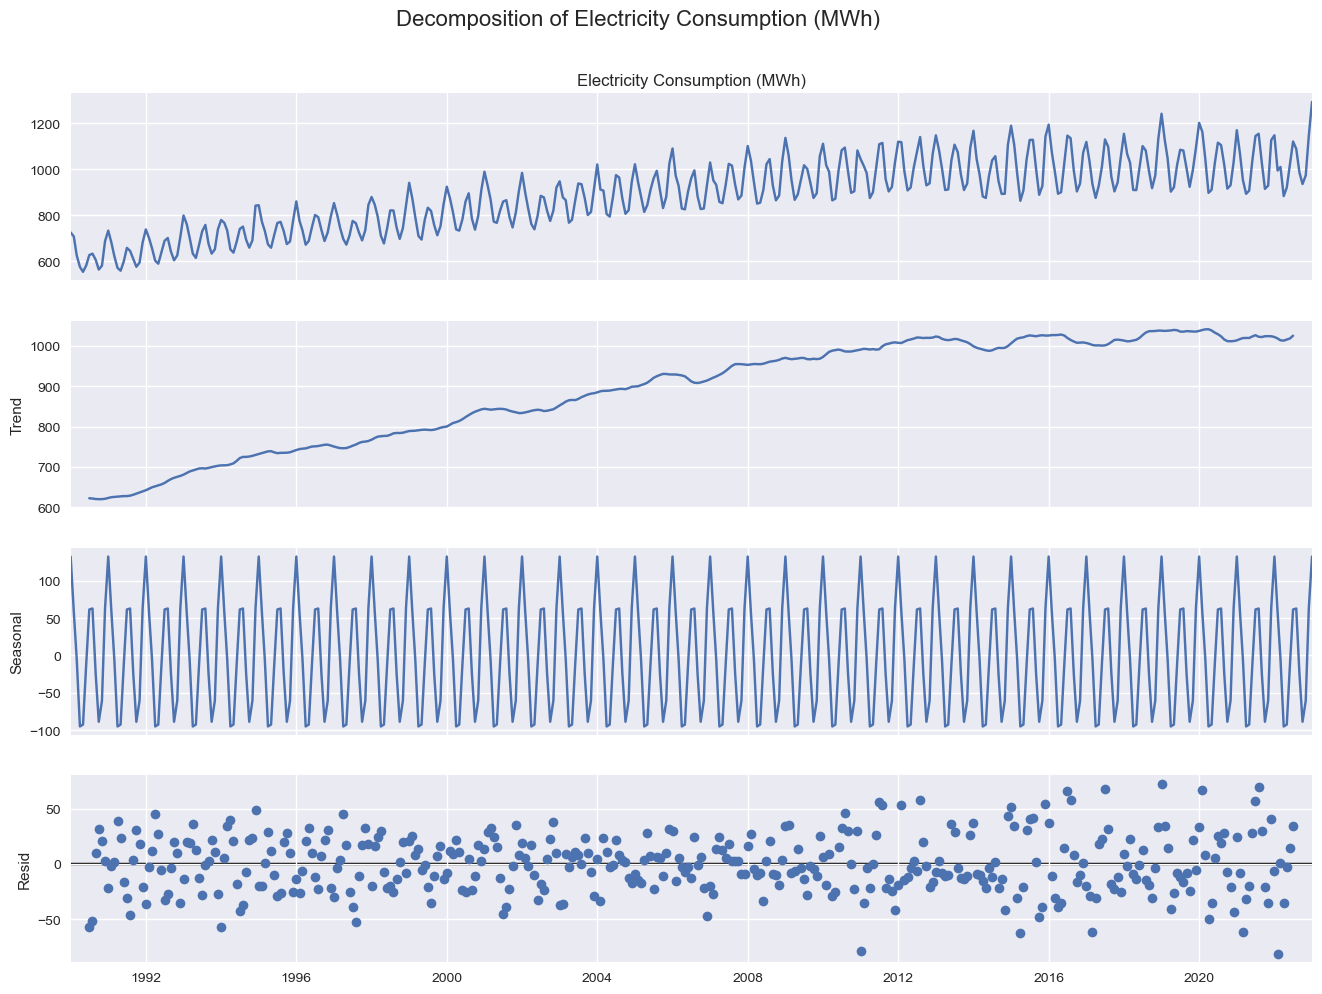

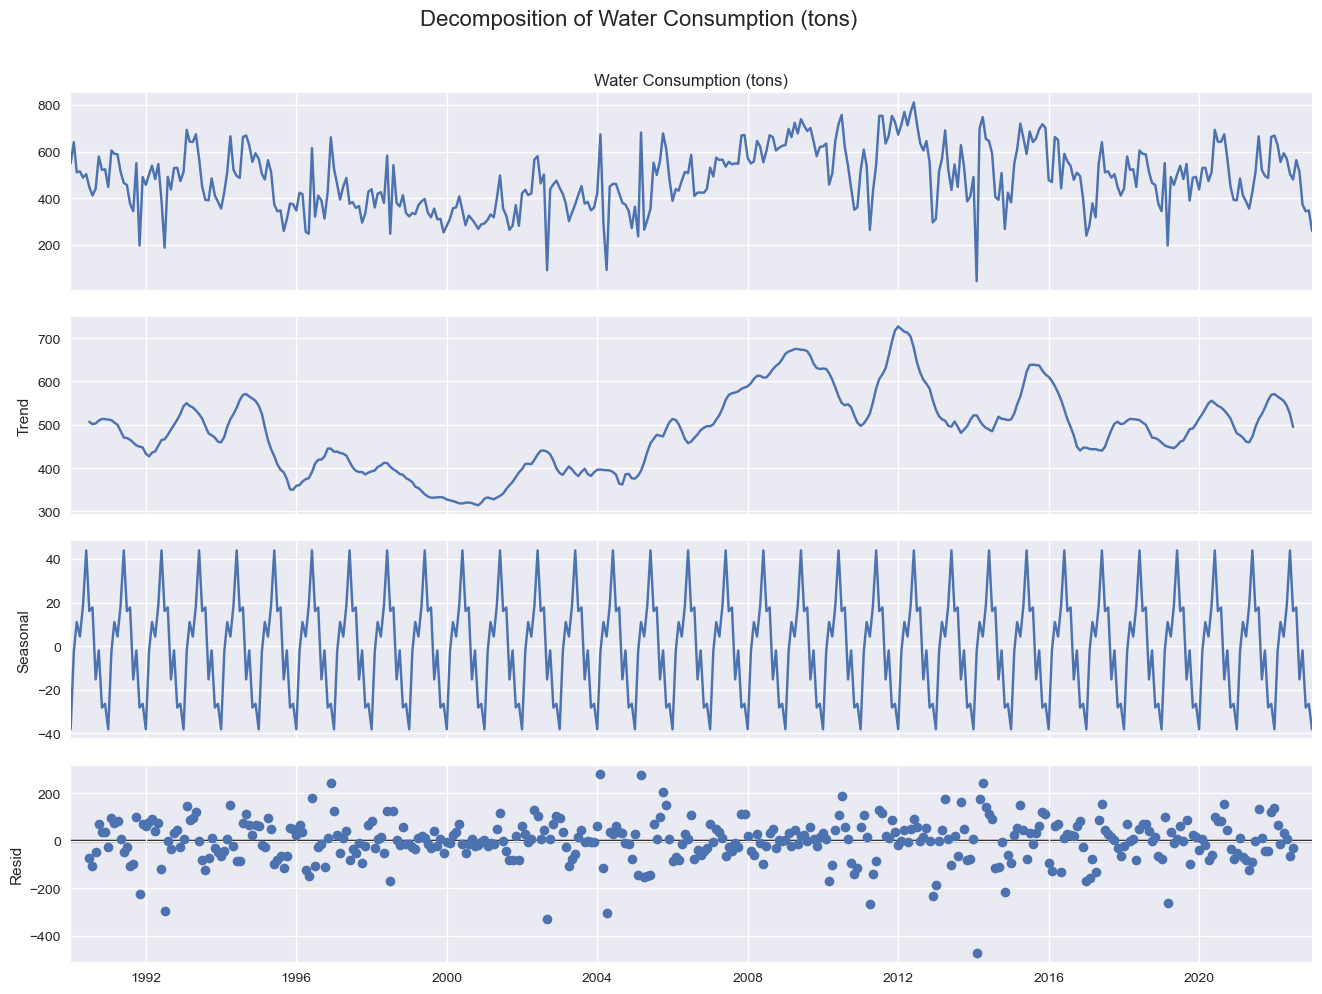

In [8]:
# Additive decomposition with a 12-month cycle
for target in targets:
    result = seasonal_decompose(df[target], model='additive', period=12)
    fig = result.plot()
    fig.set_size_inches(14, 10)
    fig.suptitle(f'Decomposition of {target}', fontsize=16, y=1.02)
    plt.show()

In [9]:
# How much of each series' month-to-month variation does the seasonal component explain?
for target in targets:
    result = seasonal_decompose(df[target], model='additive', period=12)
    detrended = df[target] - result.trend
    seasonal_share = 1 - result.resid.var() / detrended.var()
    print(f"{target}: seasonal amplitude {result.seasonal.max() - result.seasonal.min():.1f}, "
          f"seasonality explains {seasonal_share:.0%} of the detrended variation")

Gas Consumption (tons): seasonal amplitude 1.9, seasonality explains 2% of the detrended variation
Electricity Consumption (MWh): seasonal amplitude 226.9, seasonality explains 89% of the detrended variation
Water Consumption (tons): seasonal amplitude 82.0, seasonality explains 6% of the detrended variation


**Observations**

The seasonal component confirms what the plots suggested:

- **Electricity:** seasonality explains **89%** of the variation left after removing the trend. The trend component rises steadily until about 2012, then levels off. This series has the structure Holt-Winters is built for.
- **Gas:** seasonality explains only **2%**. The seasonal component swings by less than 2 tons, while the series moves by 10+ tons between years. The residual carries most of the movement, including the 2014 spike.
- **Water:** seasonality explains **6%**. Like gas, most of the movement is in the slow-moving trend and the residual.

So I expect a seasonal model to help a lot for electricity and much less for gas and water.

---
## 4. Stationarity testing

A series is stationary if its mean and variance don't change over time. ARIMA-type models need stationary data (or differencing). Holt-Winters models trend and seasonality directly, so this test is mainly to understand the data.

**Augmented Dickey-Fuller test:** H0 = non-stationary. If p < 0.05, reject H0.

In [10]:
def adf_test(series, title):
    """Augmented Dickey-Fuller test. H0: the series is non-stationary (has a unit root)."""
    result = adfuller(series.dropna())
    print(f'\n{title}:')
    print(f'  ADF statistic: {result[0]:.4f}')
    print(f'  p-value: {result[1]:.4f}')
    if result[1] <= 0.05:
        print('  -> Likely STATIONARY (reject H0)')
    else:
        print('  -> Likely NON-STATIONARY (cannot reject H0)')


for target in targets:
    adf_test(df[target], target)


Gas Consumption (tons):
  ADF statistic: -3.4044
  p-value: 0.0108
  -> Likely STATIONARY (reject H0)

Electricity Consumption (MWh):
  ADF statistic: -2.2570
  p-value: 0.1862
  -> Likely NON-STATIONARY (cannot reject H0)

Water Consumption (tons):
  ADF statistic: -4.6848
  p-value: 0.0001
  -> Likely STATIONARY (reject H0)


**Results**

- **Electricity:** non-stationary (p = 0.19). That fits its clear upward trend.
- **Gas:** stationary (p = 0.011). Over 33 years it keeps returning to a similar range, even though it wanders for years at a time.
- **Water:** stationary (p = 0.0001).

An ARIMA model would need differencing for electricity. Holt-Winters handles trend and seasonality directly, so no differencing is needed here.

---
## 5. Train, validation and test split

Time series data is split **in time order**, never shuffled, so the model is always forecasting a future it hasn't seen.

- **Test:** the last 60 months, used once at the end to measure a 60-month forecast
- **Validation:** the last 20% of the remaining months, used to choose model settings
- **Train:** everything before that

In [11]:
# Hold out the last 60 months as the test set, then split the rest 80/20 into train and validation
TEST_MONTHS = 60

n = len(df)
remaining_size = n - TEST_MONTHS
train_size = int(remaining_size * 0.8)

train = df.iloc[:train_size]
val = df.iloc[train_size:remaining_size]
test = df.iloc[remaining_size:]

print(f"Training:   {len(train)} months ({train.index[0].date()} to {train.index[-1].date()})")
print(f"Validation: {len(val)} months ({val.index[0].date()} to {val.index[-1].date()})")
print(f"Test:       {len(test)} months ({test.index[0].date()} to {test.index[-1].date()})")

Training:   269 months (1990-01-01 to 2012-05-01)
Validation: 68 months (2012-06-01 to 2018-01-01)
Test:       60 months (2018-02-01 to 2023-01-01)


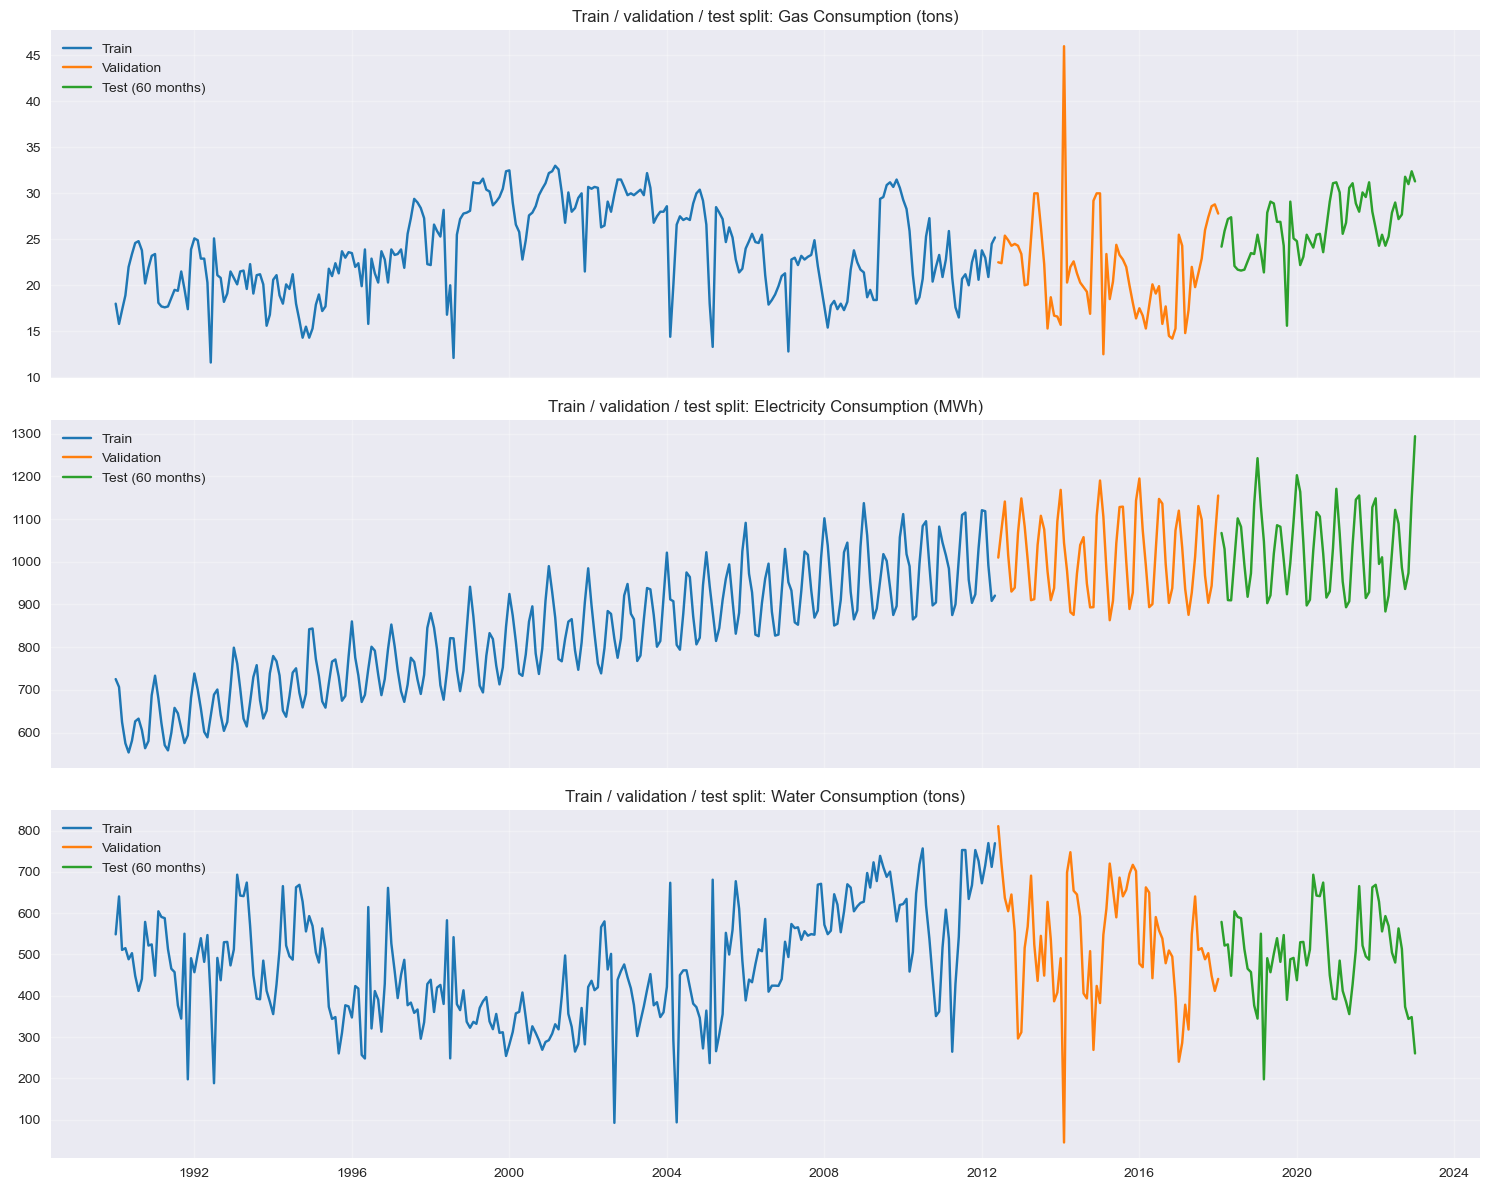

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
for idx, target in enumerate(targets):
    axes[idx].plot(train.index, train[target], label='Train', color='tab:blue')
    axes[idx].plot(val.index, val[target], label='Validation', color='tab:orange')
    axes[idx].plot(test.index, test[target], label='Test (60 months)', color='tab:green')
    axes[idx].set_title(f'Train / validation / test split: {target}', fontsize=12)
    axes[idx].legend(loc='upper left')
    axes[idx].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 6. Baseline: Simple Exponential Smoothing

A baseline gives the improved model something to beat. Simple Exponential Smoothing (SES) has no trend and no seasonality: it forecasts a flat line at the most recent smoothed level.

I also compute a **seasonal naive** benchmark that just repeats the last 12 months. If a model can't beat "same as last year", it isn't adding much.

**Metric:** MAPE (mean absolute percentage error), with MAE in each target's own units alongside it.

In [13]:
def evaluate_forecast(actual, predicted):
    """MAPE (main metric) and MAE (in the target's own units)."""
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return {
        'MAPE (%)': np.mean(np.abs((actual - predicted) / actual)) * 100,
        'MAE': np.mean(np.abs(actual - predicted)),
    }


def seasonal_naive(history, steps):
    """Benchmark: repeat the last 12 months of history."""
    return np.resize(history.iloc[-12:].values, steps)


baseline_results = []
print("--- Validation MAPE: Simple Exponential Smoothing and seasonal naive benchmark ---")

for target in targets:
    ses = SimpleExpSmoothing(train[target]).fit(optimized=True)
    ses_metrics = evaluate_forecast(val[target], ses.forecast(steps=len(val)))
    naive_metrics = evaluate_forecast(val[target], seasonal_naive(train[target], len(val)))

    baseline_results.append({'Target': target, 'Model': 'Baseline (SES)', **ses_metrics})
    print(f"\n{target}:")
    print(f"  SES:            MAPE {ses_metrics['MAPE (%)']:.2f}%")
    print(f"  Seasonal naive: MAPE {naive_metrics['MAPE (%)']:.2f}%")

--- Validation MAPE: Simple Exponential Smoothing and seasonal naive benchmark ---

Gas Consumption (tons):
  SES:            MAPE 25.42%
  Seasonal naive: MAPE 22.10%

Electricity Consumption (MWh):
  SES:            MAPE 9.79%
  Seasonal naive: MAPE 2.83%

Water Consumption (tons):
  SES:            MAPE 71.16%
  Seasonal naive: MAPE 66.38%


In [14]:
baseline_df = pd.DataFrame(baseline_results)[['Target', 'Model', 'MAPE (%)', 'MAE']]
baseline_df.round(2)

,Target,Model,MAPE (%),MAE
0,Gas Consumption (tons),Baseline (SES),25.42,4.84
1,Electricity Consumption (MWh),Baseline (SES),9.79,105.45
2,Water Consumption (tons),Baseline (SES),71.16,214.47


**Baseline results (validation, June 2012 – January 2018)**

| Target | SES MAPE | Seasonal naive MAPE |
|---|---|---|
| Gas | 25.4% | 22.1% |
| Electricity | 9.8% | 2.8% |
| Water | 71.2% | 66.4% |

- **Electricity:** the flat SES forecast cuts straight through the twice-yearly peaks and troughs. Simply repeating last year is more than three times as accurate, which shows how much of electricity is seasonality.
- **Gas** and **water:** both baselines are poor. They can't anticipate the multi-year swings.
- Water's MAPE is extreme partly because of a few very low months (section 7 looks at this).

---
## 7. Model improvement

### Step 1: Weaknesses of the baseline

- **No seasonality.** SES forecasts one flat value. For electricity, where seasonality is 89% of the detrended variation, that costs a lot: 9.8% MAPE against 2.8% for seasonal naive.
- **No trend.** SES can't project a rising or falling level, so it can't follow electricity's growth over a long horizon.
- **Gas and water** have weak seasonality (2% and 6%), so their errors come mostly from slow multi-year swings. No model built only from past values can predict when those will turn.

### Step 2: Proposed improvement: Holt-Winters

**Holt-Winters (triple exponential smoothing)** adds a trend component and a seasonal component to SES's level.

Settings to test:
- `seasonal_periods=12` for monthly data
- `trend`: additive or multiplicative
- `seasonal`: additive (fixed-size swings) or multiplicative (swings that grow with the level, which may suit electricity)
- `damped_trend`: whether the trend flattens out over time, which keeps a 60-month forecast from extrapolating growth forever

All 8 combinations are fitted on the training set and scored on the validation set. Based on the decomposition, I expect a big gain for electricity and a smaller one for gas and water.

### Step 3: Implement Holt-Winters

Gas Consumption (tons): validation MAPE = 27.06%
Electricity Consumption (MWh): validation MAPE = 2.46%


Water Consumption (tons): validation MAPE = 78.61%


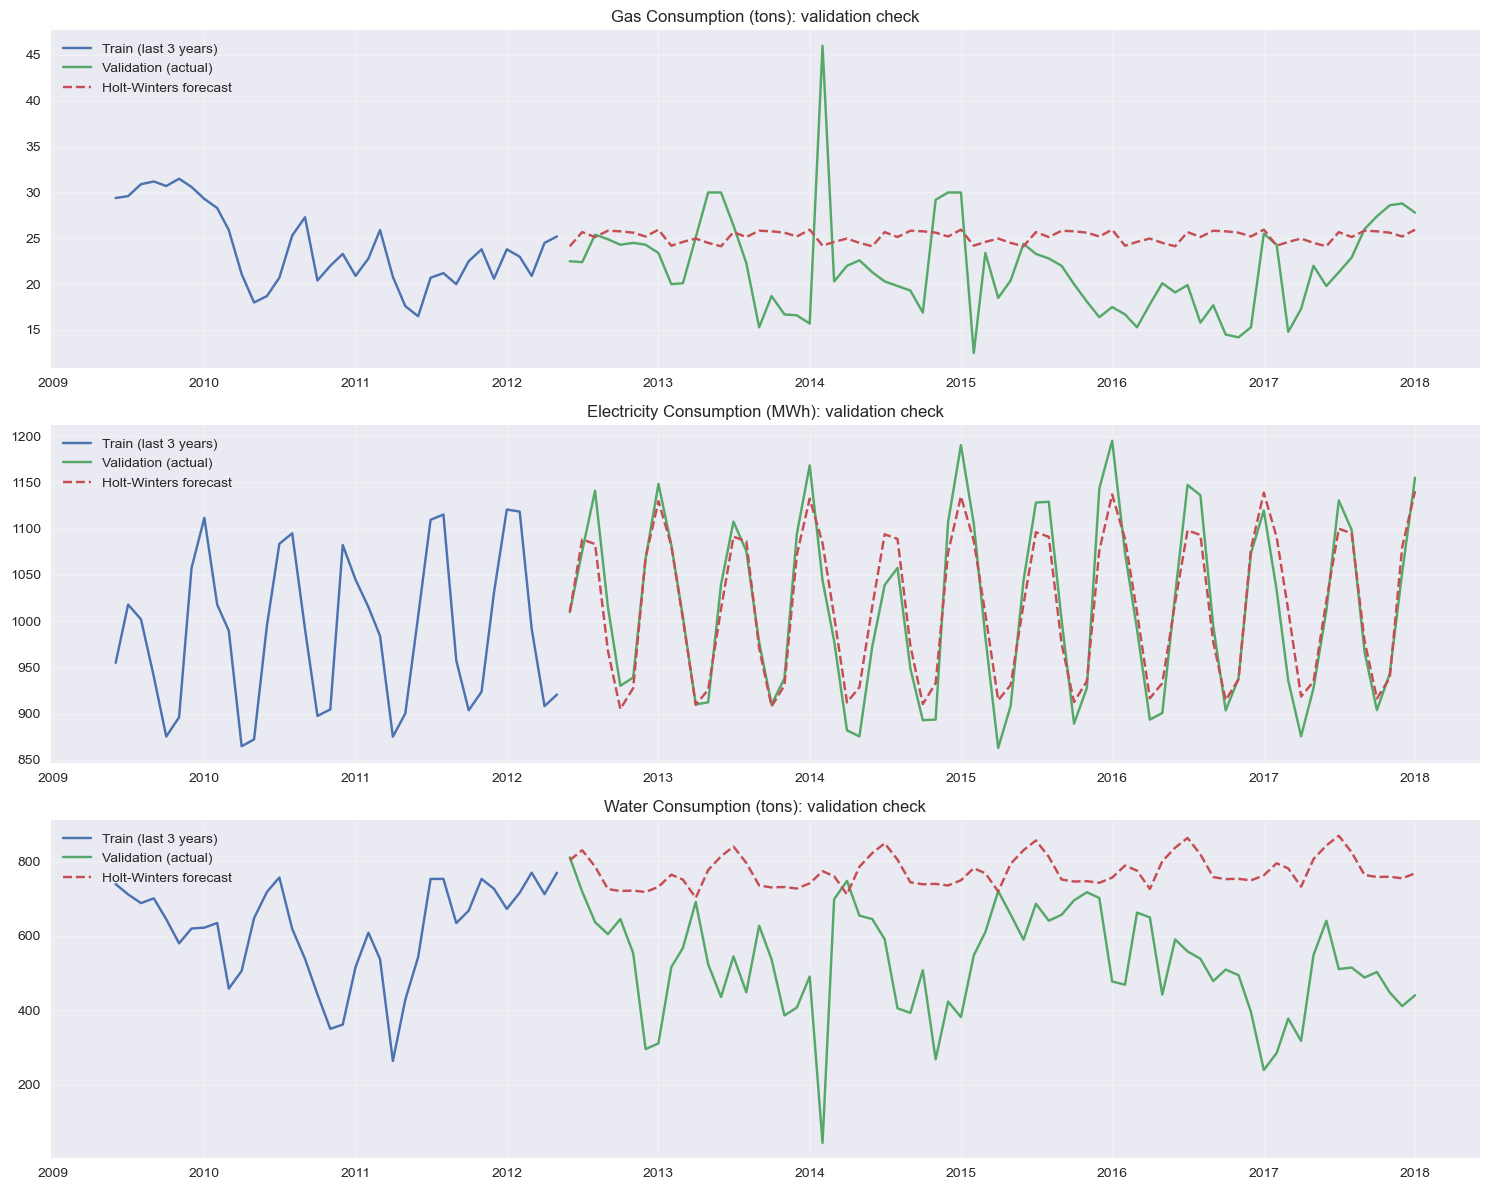

In [15]:
# First attempt: one sensible Holt-Winters configuration for every target
default_hw_results = []
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

for idx, target in enumerate(targets):
    model = ExponentialSmoothing(
        train[target],
        seasonal_periods=12,
        trend='add',
        seasonal='add',
        damped_trend=True
    ).fit(optimized=True)
    val_pred = model.forecast(steps=len(val))

    metrics = evaluate_forecast(val[target], val_pred)
    default_hw_results.append({'Target': target, 'Model': 'Holt-Winters (add, add, damped)', **metrics})
    print(f"{target}: validation MAPE = {metrics['MAPE (%)']:.2f}%")

    axes[idx].plot(train.index[-36:], train[target].tail(36), label='Train (last 3 years)')
    axes[idx].plot(val.index, val[target], label='Validation (actual)')
    axes[idx].plot(val.index, val_pred, label='Holt-Winters forecast', linestyle='--')
    axes[idx].set_title(f'{target}: validation check', fontsize=12)
    axes[idx].legend(loc='upper left')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# Tune trend type, seasonal type and damping on the validation set
param_grid = {
    'trend': ['add', 'mul'],
    'seasonal': ['add', 'mul'],
    'damped_trend': [True, False]
}
combinations = list(itertools.product(param_grid['trend'], param_grid['seasonal'], param_grid['damped_trend']))
print(f"Testing {len(combinations)} combinations per target...\n")

best_hw_configs = {}
tuned_hw_results = []

for target in targets:
    best_mape, best_params = float('inf'), None

    for trend, seasonal, damped in combinations:
        try:
            model = ExponentialSmoothing(
                train[target],
                seasonal_periods=12,
                trend=trend,
                seasonal=seasonal,
                damped_trend=damped
            ).fit(optimized=True)
            mape = evaluate_forecast(val[target], model.forecast(steps=len(val)))['MAPE (%)']
        except Exception:
            # Skip combinations that fail to fit
            continue

        if mape < best_mape:
            best_mape = mape
            best_params = {'trend': trend, 'seasonal': seasonal, 'damped_trend': damped}

    best_hw_configs[target] = best_params
    tuned_hw_results.append({
        'Target': target,
        'Model': f"Tuned H-W ({best_params['trend']}, {best_params['seasonal']}, damped={best_params['damped_trend']})",
        'MAPE (%)': best_mape
    })
    print(f"{target}")
    print(f"  Best params: {best_params}")
    print(f"  Best validation MAPE: {best_mape:.2f}%")

Testing 8 combinations per target...



Gas Consumption (tons)
  Best params: {'trend': 'mul', 'seasonal': 'add', 'damped_trend': False}
  Best validation MAPE: 18.06%


Electricity Consumption (MWh)
  Best params: {'trend': 'add', 'seasonal': 'add', 'damped_trend': True}
  Best validation MAPE: 2.46%


Water Consumption (tons)
  Best params: {'trend': 'add', 'seasonal': 'mul', 'damped_trend': True}
  Best validation MAPE: 74.17%


`GridSearchCV` doesn't fit time series models like Holt-Winters, because it shuffles data into folds. So the search is a simple loop that fits on the training set and scores on the validation set, keeping time order.

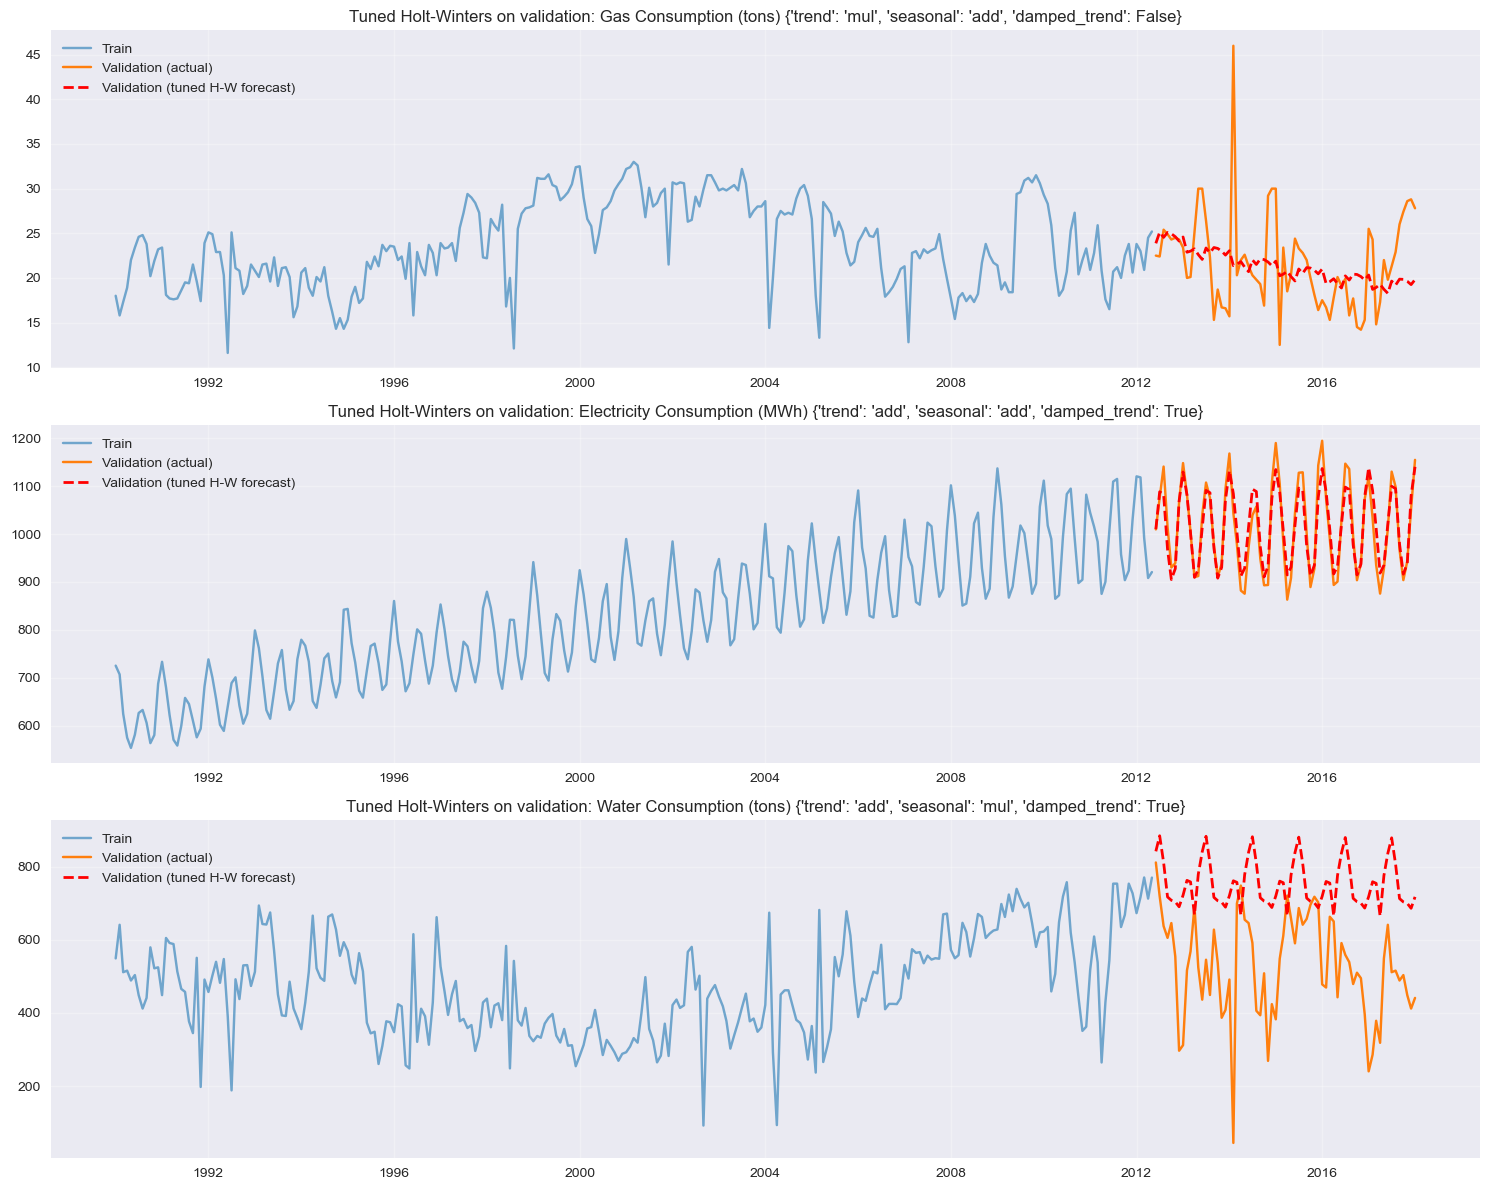

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

for idx, target in enumerate(targets):
    params = best_hw_configs[target]
    model = ExponentialSmoothing(
        train[target],
        seasonal_periods=12,
        trend=params['trend'],
        seasonal=params['seasonal'],
        damped_trend=params['damped_trend']
    ).fit(optimized=True)
    val_forecast = model.forecast(steps=len(val))

    axes[idx].plot(train.index, train[target], label='Train', color='tab:blue', alpha=0.6)
    axes[idx].plot(val.index, val[target], label='Validation (actual)', color='tab:orange')
    axes[idx].plot(val.index, val_forecast, label='Validation (tuned H-W forecast)', color='red', linestyle='--', linewidth=2)
    axes[idx].set_title(f'Tuned Holt-Winters on validation: {target} {params}', fontsize=12)
    axes[idx].legend(loc='upper left')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Step 4: Compare baseline and tuned Holt-Winters

In [18]:
comparison_df = pd.DataFrame(baseline_results + tuned_hw_results)[['Target', 'Model', 'MAPE (%)']]
comparison_df = comparison_df.sort_values(by=['Target', 'MAPE (%)'], ascending=[True, False])
print("--- Validation MAPE: baseline (SES) vs tuned Holt-Winters ---")
comparison_df.round(2)

--- Validation MAPE: baseline (SES) vs tuned Holt-Winters ---


,Target,Model,MAPE (%)
1,Electricity Consumption (MWh),Baseline (SES),9.79
4,Electricity Consumption (MWh),"Tuned H-W (add, add, damped=True)",2.46
0,Gas Consumption (tons),Baseline (SES),25.42
3,Gas Consumption (tons),"Tuned H-W (mul, add, damped=False)",18.06
5,Water Consumption (tons),"Tuned H-W (add, mul, damped=True)",74.17
2,Water Consumption (tons),Baseline (SES),71.16


In [19]:
for target in targets:
    baseline_mape = next(r for r in baseline_results if r['Target'] == target)['MAPE (%)']
    improved_mape = next(r for r in tuned_hw_results if r['Target'] == target)['MAPE (%)']
    change = baseline_mape - improved_mape

    print(f"\n{target}:")
    print(f"  Baseline MAPE: {baseline_mape:.2f}%")
    print(f"  Tuned H-W MAPE: {improved_mape:.2f}%")
    if change > 0:
        print(f"  -> Improved by {change:.2f} points ({change / baseline_mape * 100:.1f}% reduction)")
    else:
        print(f"  -> No improvement: Holt-Winters is {-change:.2f} points worse")


Gas Consumption (tons):
  Baseline MAPE: 25.42%
  Tuned H-W MAPE: 18.06%
  -> Improved by 7.36 points (29.0% reduction)

Electricity Consumption (MWh):
  Baseline MAPE: 9.79%
  Tuned H-W MAPE: 2.46%
  -> Improved by 7.33 points (74.9% reduction)

Water Consumption (tons):
  Baseline MAPE: 71.16%
  Tuned H-W MAPE: 74.17%
  -> No improvement: Holt-Winters is 3.01 points worse


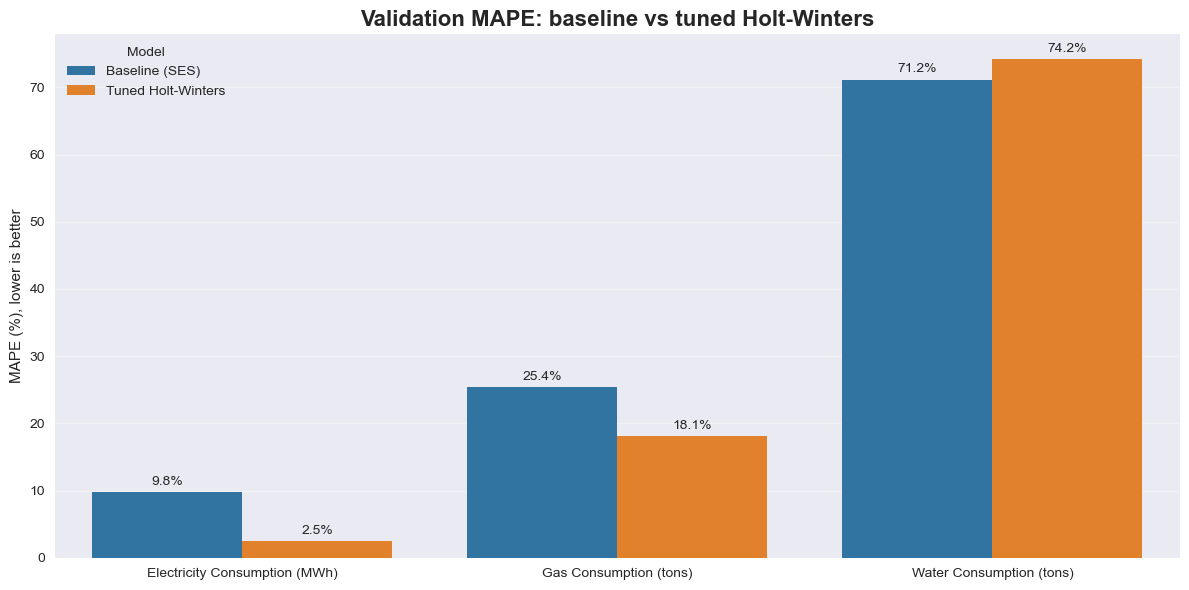

In [20]:
plt.figure(figsize=(12, 6))
plot_df = comparison_df.copy()
plot_df['Model'] = plot_df['Model'].where(plot_df['Model'] == 'Baseline (SES)', 'Tuned Holt-Winters')
ax = sns.barplot(data=plot_df, x='Target', y='MAPE (%)', hue='Model', palette='tab10')
plt.title('Validation MAPE: baseline vs tuned Holt-Winters', fontsize=16, fontweight='bold')
plt.ylabel('MAPE (%), lower is better')
plt.xlabel('')
plt.grid(axis='y', alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)
plt.tight_layout()
plt.show()

### Step 5: Discussion

| Target | Baseline (SES) | Tuned Holt-Winters | Change |
|---|---|---|---|
| Electricity | 9.8% | **2.5%** (add, add, damped) | 75% lower error |
| Gas | 25.4% | **18.1%** (mul, add, not damped) | 29% lower error |
| Water | **71.2%** | 74.2% (add, mul, damped) | 3 points worse |

- **Electricity:** the improvement worked as expected. Modelling the two seasonal peaks and the damped trend brings validation MAPE from 9.8% down to 2.5%, slightly better than seasonal naive (2.8%). The default configuration (additive, damped) was already the best one.
- **Gas:** tuning mattered. The default configuration scored 27.1%, worse than the baseline, while the tuned one reached 18.1%. It also beats seasonal naive (22.1%), but the gain mostly comes from tracking the level better, not from seasonality, which gas barely has.
- **Water:** Holt-Winters didn't help. With almost no seasonality to capture, the extra components mostly add noise to the forecast.

The cell below checks how much water's MAPE depends on a few unusual months.

In [21]:
# Water's validation MAPE is driven by a few very low months.
# Absolute percentage error per month for the tuned Holt-Winters forecast:
target = 'Water Consumption (tons)'
params = best_hw_configs[target]
model = ExponentialSmoothing(train[target], seasonal_periods=12, trend=params['trend'],
                             seasonal=params['seasonal'], damped_trend=params['damped_trend']).fit(optimized=True)
ape = (np.abs(val[target] - model.forecast(steps=len(val))) / val[target] * 100)

print(f"Validation MAPE: {ape.mean():.1f}%   Median APE: {ape.median():.1f}%")
print("\nWorst five months:")
print(pd.DataFrame({'Actual': val[target], 'APE (%)': ape}).nlargest(5, 'APE (%)').round(1))

Validation MAPE: 74.2%   Median APE: 43.9%

Worst five months:
            Actual  APE (%)
DATE                       
2014-02-01    44.4   1613.9
2017-01-01   240.1    198.9
2017-02-01   285.6    165.5
2014-11-01   268.7    161.1
2012-12-01   296.4    132.8


Most of water's high MAPE comes from a few months. In **February 2014**, actual consumption was 44.4 tons. Any normal forecast misses that by over 1,000%, and that one month adds about 24 points to the 68-month average. The median error is 43.9%, still high but much lower than the mean.

MAPE punishes errors on very small actual values heavily, so for water I also report MAE in tons in the final evaluation.

---
## 8. Final evaluation: 60-month forecast

In [22]:
# Pick the model with the lowest validation MAPE for each target
best_models_summary = comparison_df.loc[comparison_df.groupby('Target')['MAPE (%)'].idxmin()]
print("--- Selected models (lowest validation MAPE) ---")
display(best_models_summary.round(2))

final_model_selection = {}
for _, row in best_models_summary.iterrows():
    if row['Model'].startswith('Tuned H-W'):
        final_model_selection[row['Target']] = {'type': 'Holt-Winters', 'params': best_hw_configs[row['Target']]}
    else:
        final_model_selection[row['Target']] = {'type': 'SES'}

for t, conf in final_model_selection.items():
    print(f"  {t} -> {conf['type']} {conf.get('params', '')}")

--- Selected models (lowest validation MAPE) ---


,Target,Model,MAPE (%)
4,Electricity Consumption (MWh),"Tuned H-W (add, add, damped=True)",2.46
3,Gas Consumption (tons),"Tuned H-W (mul, add, damped=False)",18.06
2,Water Consumption (tons),Baseline (SES),71.16


  Electricity Consumption (MWh) -> Holt-Winters {'trend': 'add', 'seasonal': 'add', 'damped_trend': True}
  Gas Consumption (tons) -> Holt-Winters {'trend': 'mul', 'seasonal': 'add', 'damped_trend': False}
  Water Consumption (tons) -> SES 


**Selection:** the model with the lowest validation MAPE for each target.

- **Electricity:** tuned Holt-Winters (2.5%)
- **Gas:** tuned Holt-Winters (18.1%)
- **Water:** the SES baseline (71.2%), because Holt-Winters didn't beat it on validation

I keep this rule even where it picks the simpler model. Choosing models by looking at the test set would make the final score look better than it really is.

### Forecasting the 60 test months

Each selected model is refitted on train + validation, then forecasts all 60 test months at once. The test set hasn't been used for any choice up to this point.

In [23]:
def fit_model(series, selection):
    """Fit the selected model type on a series."""
    if selection['type'] == 'Holt-Winters':
        p = selection['params']
        return ExponentialSmoothing(
            series,
            seasonal_periods=12,
            trend=p['trend'],
            seasonal=p['seasonal'],
            damped_trend=p['damped_trend']
        ).fit(optimized=True)
    return SimpleExpSmoothing(series).fit(optimized=True)


# Refit on train + validation, then forecast all 60 test months in one go
train_val_combined = pd.concat([train, val])
final_forecast_values = pd.DataFrame(index=test.index)
final_test_scores = []

for target in targets:
    selection = final_model_selection[target]
    final_model = fit_model(train_val_combined[target], selection)
    final_forecast_values[target] = final_model.forecast(steps=len(test))

    model_scores = evaluate_forecast(test[target], final_forecast_values[target])
    naive_scores = evaluate_forecast(test[target], seasonal_naive(train_val_combined[target], len(test)))
    final_test_scores.append({
        'Target': target,
        'Model': selection['type'],
        'Test MAPE (%)': model_scores['MAPE (%)'],
        'Test MAE': model_scores['MAE'],
        'Seasonal naive MAPE (%)': naive_scores['MAPE (%)'],
    })

final_df = pd.DataFrame(final_test_scores)
print("--- 60-month test results ---")
final_df.round(2)

--- 60-month test results ---


,Target,Model,Test MAPE (%),Test MAE,Seasonal naive MAPE (%)
0,Gas Consumption (tons),Holt-Winters,18.82,5.19,18.41
1,Electricity Consumption (MWh),Holt-Winters,2.87,30.78,3.49
2,Water Consumption (tons),SES,19.42,92.97,22.68


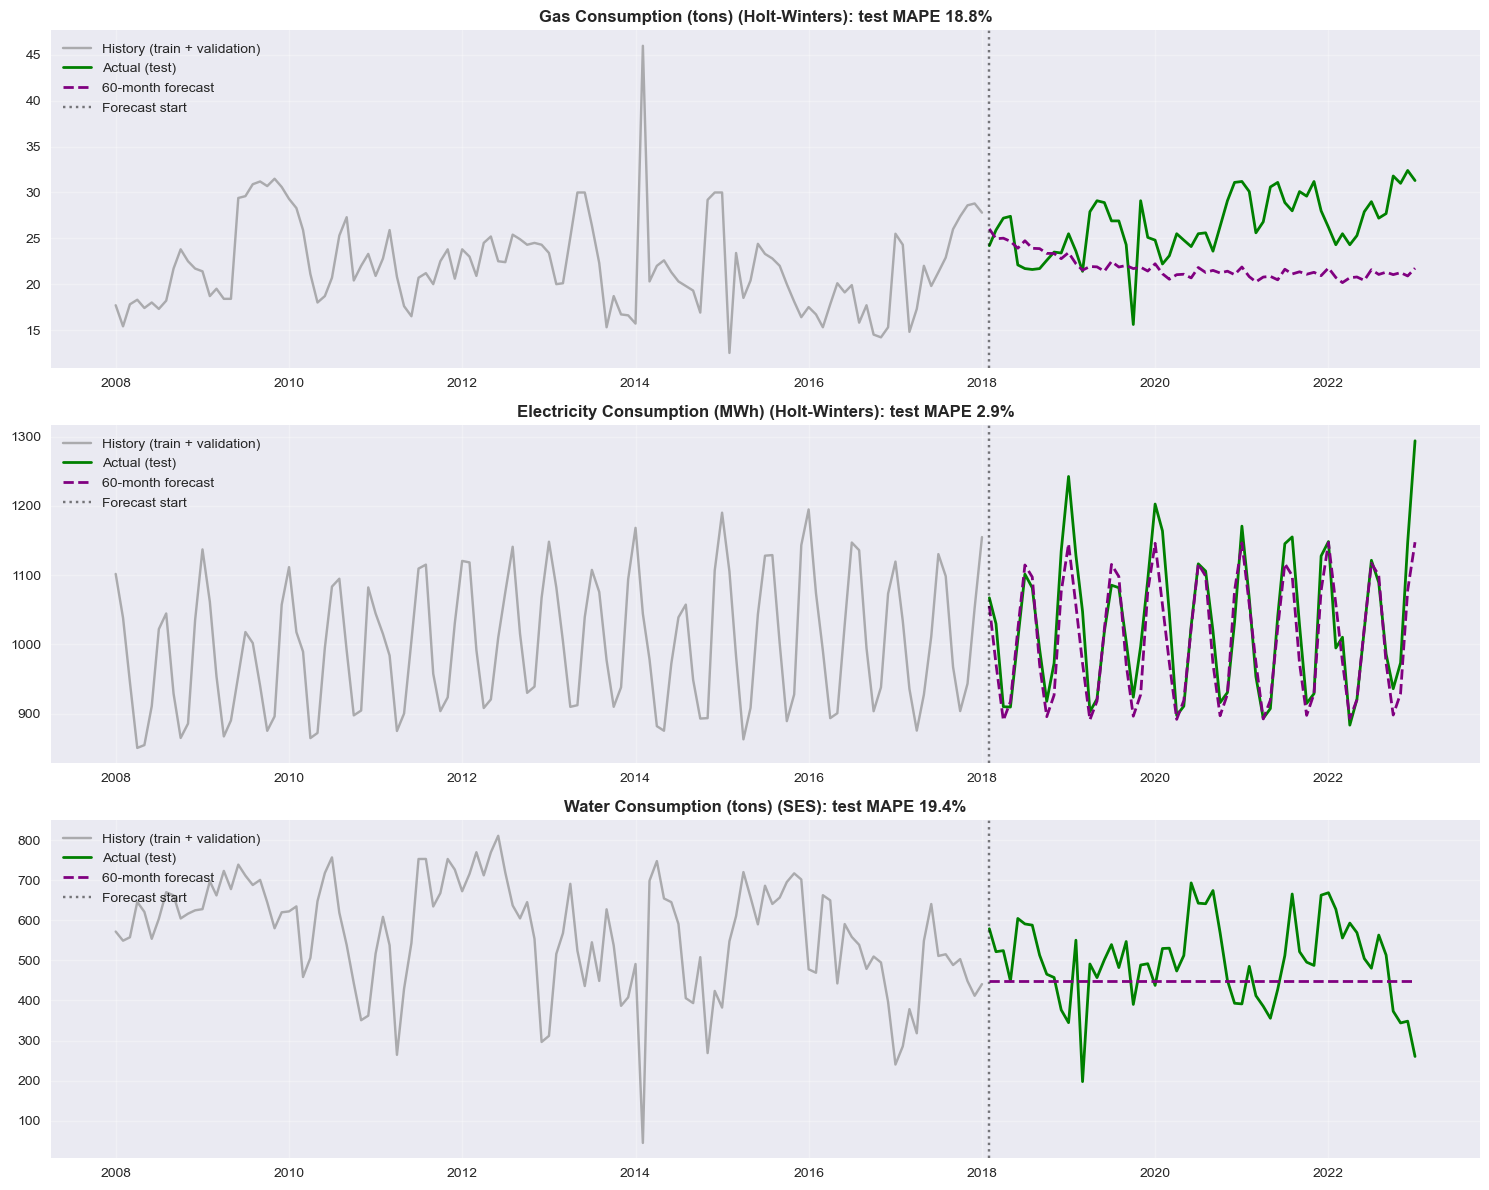

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

for idx, target in enumerate(targets):
    history = train_val_combined[target].loc['2008':]
    axes[idx].plot(history.index, history, label='History (train + validation)', color='gray', alpha=0.6)
    axes[idx].plot(test.index, test[target], label='Actual (test)', color='green', linewidth=2)
    axes[idx].plot(test.index, final_forecast_values[target], label='60-month forecast', color='purple', linestyle='--', linewidth=2)
    axes[idx].axvline(x=test.index[0], color='black', linestyle=':', alpha=0.5, label='Forecast start')

    row = final_df[final_df['Target'] == target].iloc[0]
    axes[idx].set_title(f"{target} ({row['Model']}): test MAPE {row['Test MAPE (%)']:.1f}%", fontsize=12, fontweight='bold')
    axes[idx].legend(loc='upper left')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**60-month test results (February 2018 – January 2023)**

| Target | Model | Test MAPE | Test MAE | Seasonal naive MAPE |
|---|---|---|---|---|
| Electricity | Holt-Winters | **2.9%** | 31 MWh | 3.5% |
| Gas | Holt-Winters | 18.8% | 5.2 tons | 18.4% |
| Water | SES | 19.4% | 93 tons | 22.7% |

- **Electricity:** a strong result. The forecast follows both yearly peaks for five years and beats the seasonal naive benchmark. Its biggest misses are the highest winter peaks (January 2019 and January 2023), which come in above the forecast.
- **Gas:** no better than repeating last year. The forecast stays around 21 tons while actual consumption rises to around 30 by 2022. Nothing in the gas history signals that rise in advance.
- **Water:** the flat SES forecast (about 450 tons) beats seasonal naive. But the water series from May 2017 onwards repeats the values from January 1990 onwards exactly. 98% of the test months match October 1990 – September 1995. So the water data looks partly synthetic, and its result shouldn't be read as a real-world forecast.

---
## 9. Residual diagnostics

A model that has captured the structure should leave residuals that look like random noise: centred on zero, with no leftover autocorrelation (Ljung-Box test) and roughly normal (Shapiro-Wilk test).

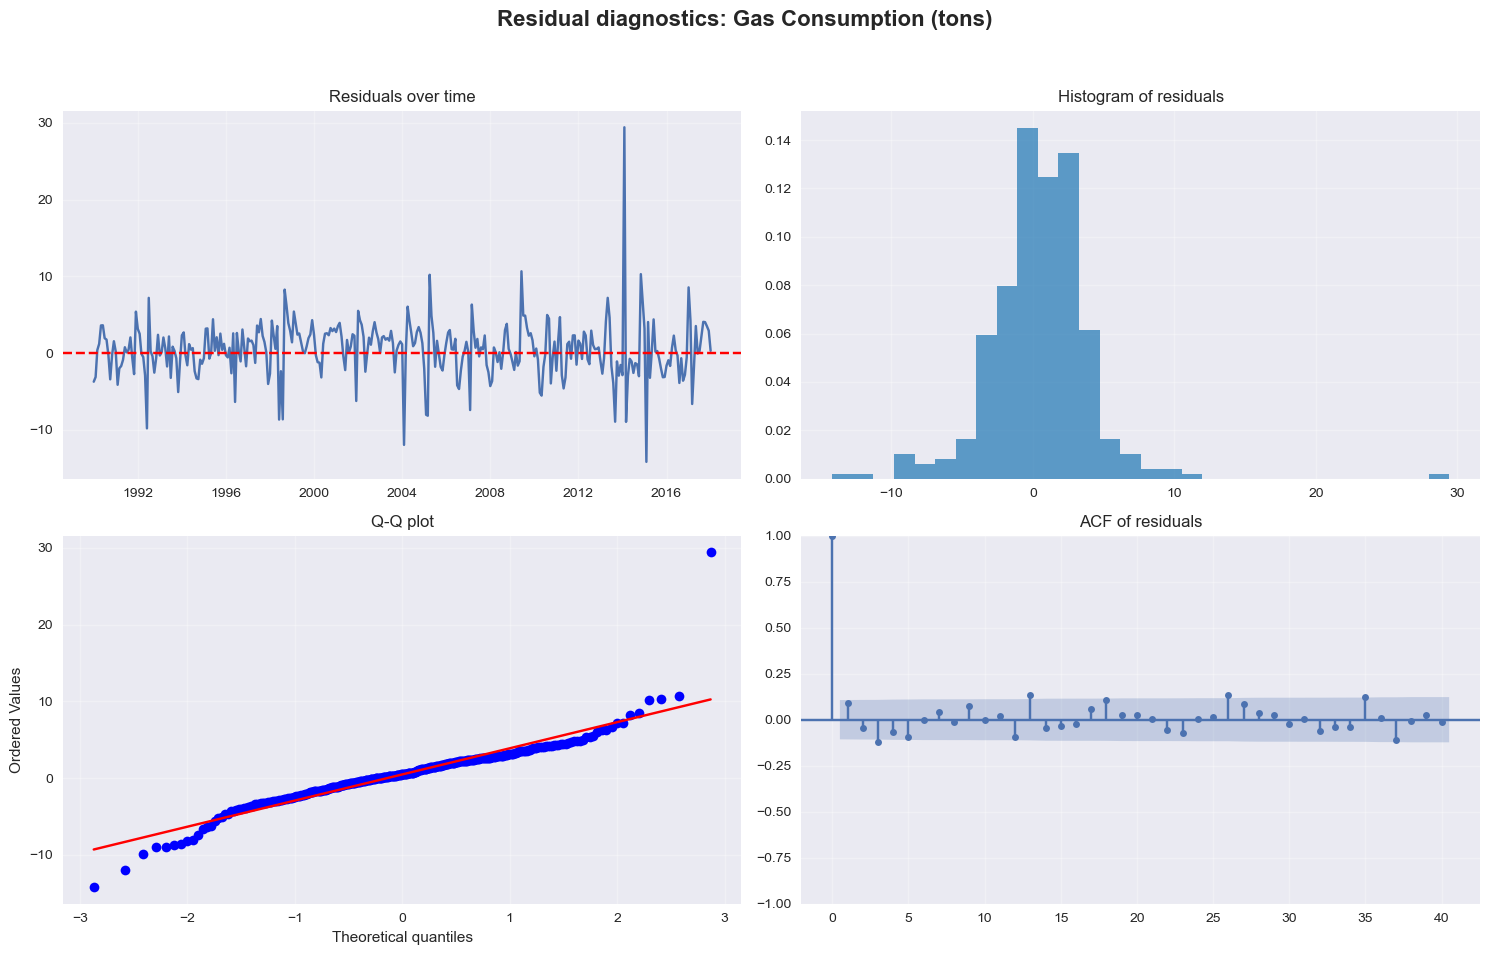

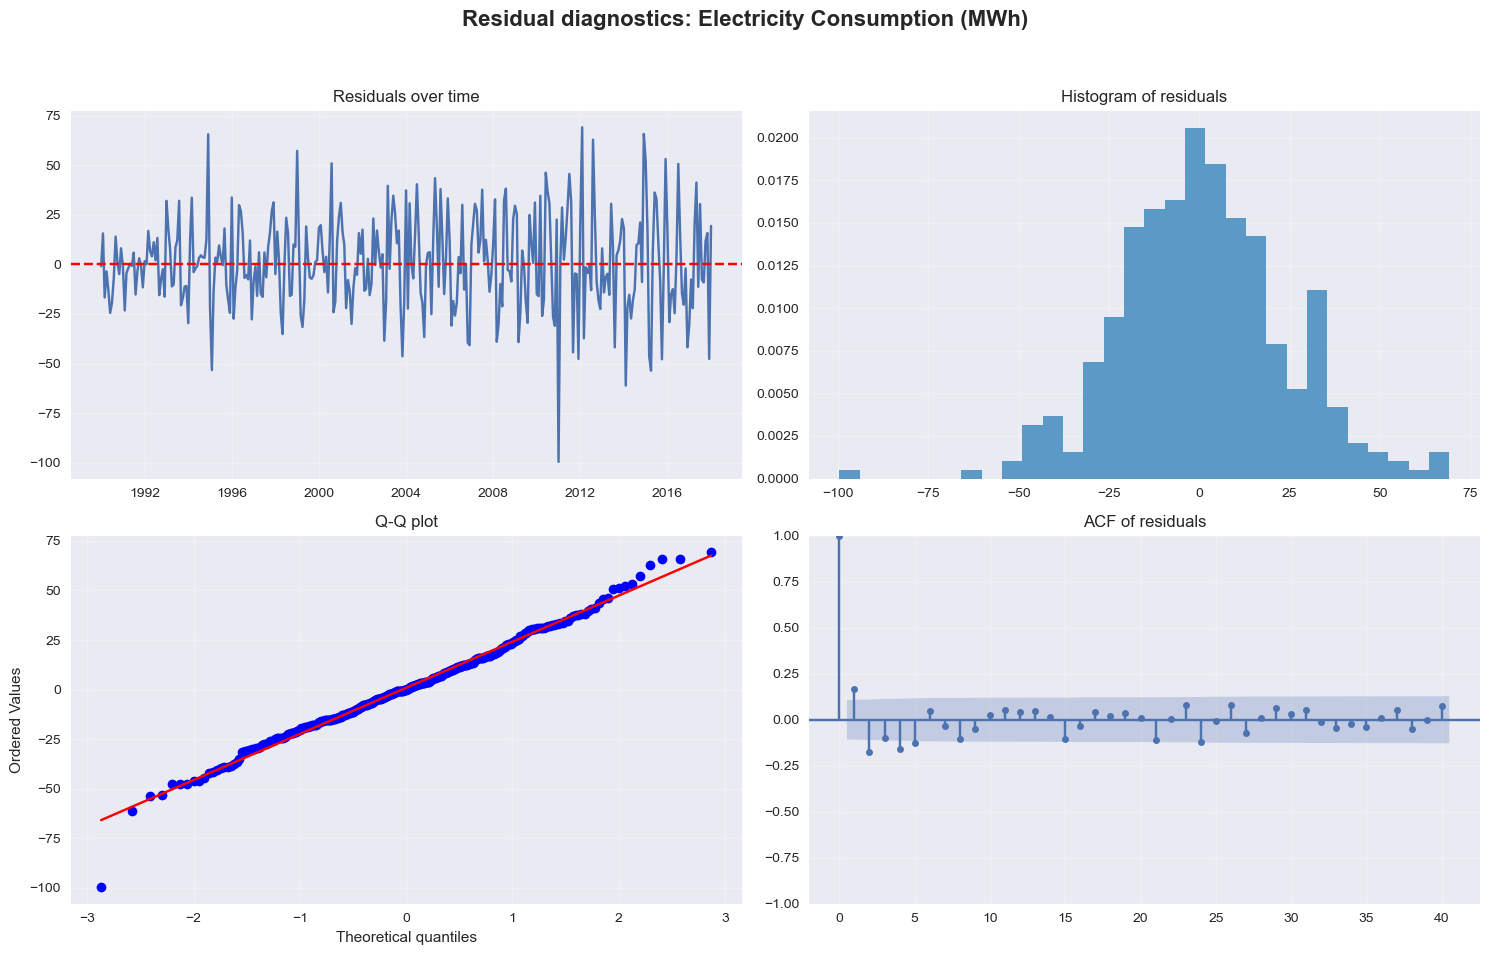

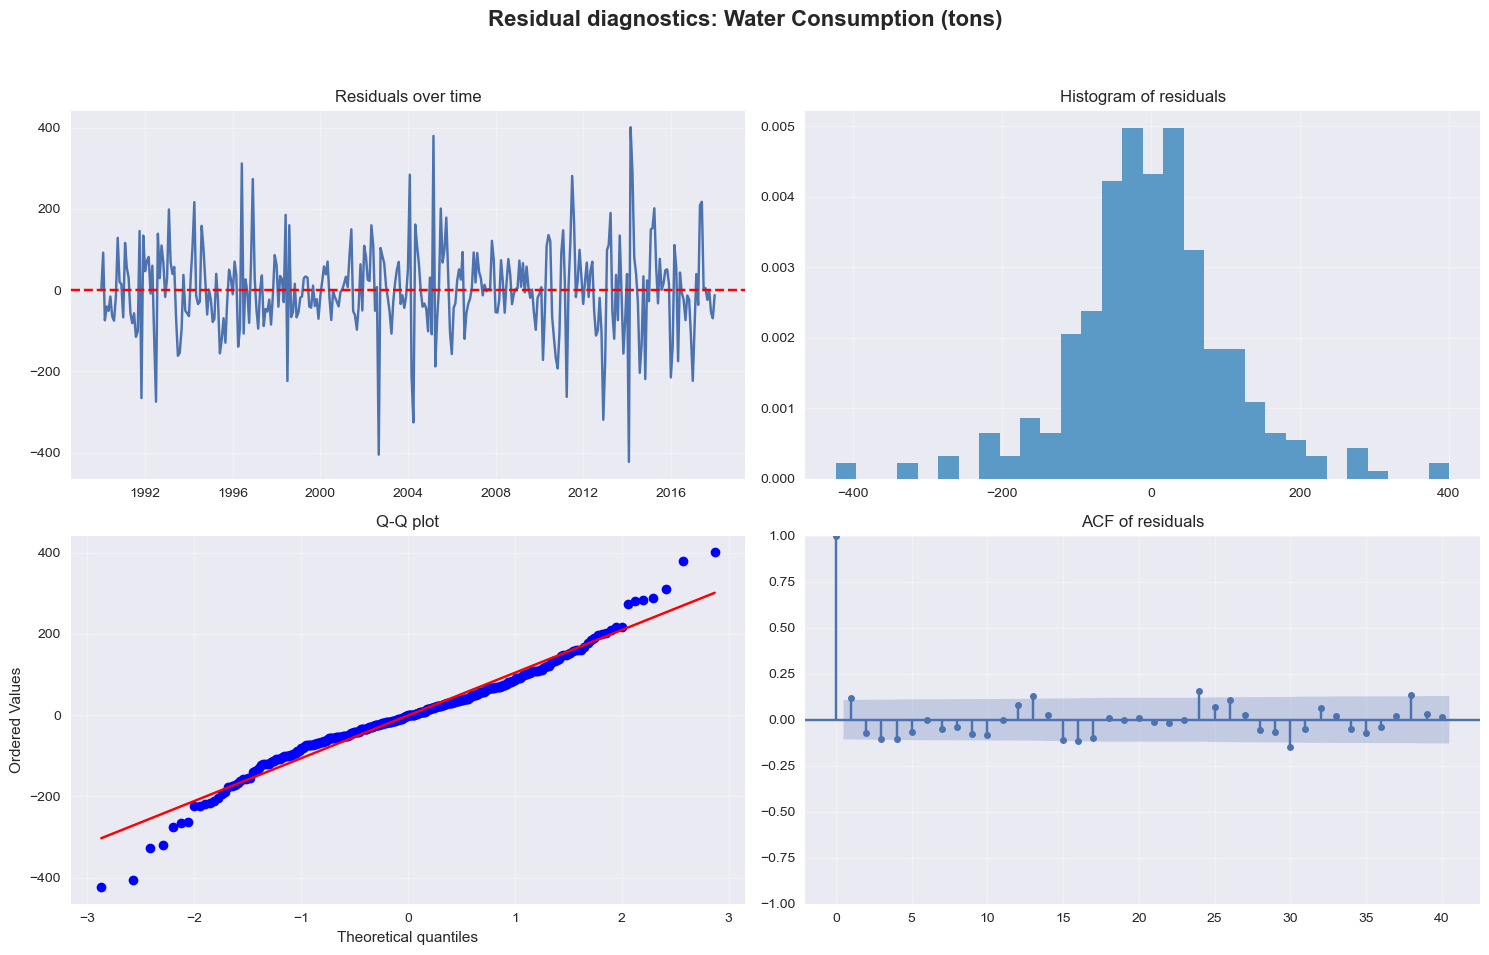

In [25]:
for target in targets:
    model = fit_model(train_val_combined[target], final_model_selection[target])
    residuals = model.resid

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f'Residual diagnostics: {target}', fontsize=16, fontweight='bold')

    axes[0, 0].plot(residuals)
    axes[0, 0].axhline(y=0, color='red', linestyle='--')
    axes[0, 0].set_title('Residuals over time')
    axes[0, 0].grid(True, alpha=0.3)

    axes[0, 1].hist(residuals, bins=30, density=True, alpha=0.7, color='tab:blue')
    axes[0, 1].set_title('Histogram of residuals')
    axes[0, 1].grid(True, alpha=0.3)

    stats.probplot(residuals, dist='norm', plot=axes[1, 0])
    axes[1, 0].set_title('Q-Q plot')
    axes[1, 0].grid(True, alpha=0.3)

    plot_acf(residuals, lags=40, ax=axes[1, 1])
    axes[1, 1].set_title('ACF of residuals')
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

In [26]:
print("--- Residual statistics ---")
for target in targets:
    model = fit_model(train_val_combined[target], final_model_selection[target])
    residuals = model.resid
    _, shapiro_p = shapiro(residuals)
    ljung_p = acorr_ljungbox(residuals, lags=[12])['lb_pvalue'].iloc[0]

    print(f"\n{target} ({final_model_selection[target]['type']}):")
    print(f"  Mean: {residuals.mean():.2f}   Std dev: {residuals.std():.2f}")
    print(f"  Shapiro-Wilk p-value: {shapiro_p:.4f} ({'normal' if shapiro_p > 0.05 else 'not normal'})")
    print(f"  Ljung-Box p-value (lag 12): {ljung_p:.4f} "
          f"({'no leftover autocorrelation' if ljung_p > 0.05 else 'leftover autocorrelation'})")

--- Residual statistics ---

Gas Consumption (tons) (Holt-Winters):
  Mean: 0.48   Std dev: 3.61
  Shapiro-Wilk p-value: 0.0000 (not normal)
  Ljung-Box p-value (lag 12): 0.0999 (no leftover autocorrelation)

Electricity Consumption (MWh) (Holt-Winters):
  Mean: 0.87   Std dev: 23.25
  Shapiro-Wilk p-value: 0.0434 (not normal)
  Ljung-Box p-value (lag 12): 0.0000 (leftover autocorrelation)

Water Consumption (tons) (SES):
  Mean: -0.75   Std dev: 106.66
  Shapiro-Wilk p-value: 0.0000 (not normal)
  Ljung-Box p-value (lag 12): 0.0229 (leftover autocorrelation)


**Observations**

- **Gas:** no significant leftover autocorrelation (Ljung-Box p = 0.10), so the model has captured the patterns it can. The residuals aren't normal because of one-off shocks such as the 2014 spike.
- **Electricity:** residuals are only mildly non-normal (Shapiro-Wilk p = 0.04), but there is leftover autocorrelation (Ljung-Box p < 0.001). The two-peak seasonal shape changes slightly over the years, and a fixed seasonal pattern can't fully follow it.
- **Water:** some leftover autocorrelation (p = 0.02), as expected from a model with no trend or seasonality. The residuals are far from normal because of the very low outlier months.
- All residual means are close to zero relative to each series' scale, so none of the models is strongly biased.

---
## 10. Conclusion

**Goal:** forecast 60 months of gas, electricity and water consumption from 33 years of monthly data.

**What worked**
- **Electricity is forecastable.** It has a strong trend and a clear twice-yearly seasonal cycle. Tuned Holt-Winters reached **2.9% MAPE over 60 months**, better than both the SES baseline and the seasonal naive benchmark.
- Tuning beat guessing: for gas, the default Holt-Winters configuration was worse than the baseline, while the tuned one was 29% better on validation.

**What didn't**
- **Gas and water** have almost no seasonality (2% and 6% of detrended variation). Their movement comes from multi-year swings that past values alone can't predict. Gas ended up no better than "same as last year".
- For water, Holt-Winters didn't beat the simple baseline, and the test period turned out to repeat early-1990s data.

**Lessons**
- **Check the data before trusting the model.** My first version parsed the dates wrongly, interpolated 91% of the months, and produced results that looked better than these. An assertion that every month has a real reading now catches that.
- **Always compare against a naive benchmark.** Beating your own weak baseline isn't enough. Beating "same as last year" shows the model adds something.
- **MAPE can mislead** when a series has very small values. MAE and the median error give a fuller picture.

**Next steps**
- Add outside variables, such as temperature (heating and cooling degree days), which likely drive electricity's two peaks
- Try SARIMA and compare it with Holt-Winters on electricity
- Use rolling-origin evaluation (several forecast start points) instead of a single split
- Report prediction intervals, not just point forecasts